**Table of contents**<a id='toc0_'></a>    
- 1. [Preface](#toc1_)    
- 2. [Import packages](#toc2_)    
- 3. [Train demo](#toc3_)    
- 4. [Data](#toc4_)    
  - 4.1. [Data](#toc4_1_)    
  - 4.2. [dataset](#toc4_2_)    
    - 4.2.1. [Creating Graph Dataset](#toc4_2_1_)    
    - 4.2.2. [Dataset split](#toc4_2_2_)    
  - 4.3. [visualization](#toc4_3_)    
    - 4.3.1. [Networkx](#toc4_3_1_)    
    - 4.3.2. [Pyhton-igraph](#toc4_3_2_)    
  - 4.4. [dataloader](#toc4_4_)    
- 5. [Model](#toc5_)    
- 6. [Train](#toc6_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# 1. <a id='toc1_'></a>[Preface](#toc0_)

图神经网络学习笔记。

什么是图神经网络 (GNNs)？
- 只更新图的`参数`；
- 不改变图的`结构`。

# 2. <a id='toc2_'></a>[Import packages](#toc0_)

In [1]:
# %config InlineBackend.figure_format = "svg"

import matplotlib.pyplot as plt
from deepspore.matplotlib_config import set_plt_rcParams
set_plt_rcParams()


import torch

import networkx as nx


def visualization(edglist: torch.Tensor, figsize: tuple = (2.5, 2.5)) -> None:
    '''Draw the graphcal plot with matplotlib.
    Args:
        edglist: torch.Tensor, COO format graph file.
        figsize: tuple, figure size.
    Return: None
    '''
    G = nx.Graph() # Undirect graph
    G.add_edges_from(edglist.T.tolist())
    plt.figure(figsize=figsize)
    nx.draw(G, pos=nx.spring_layout(G, seed=123), 
            node_size=100, node_color='lightblue', edgecolors='black',
            with_labels=True, font_size=6, font_family='Arial', 
            edge_color='gray')


2025-09-28 10:14:27.350 | INFO     | deepspore.matplotlib_config:set_plt_rcParams:52 - Set configure for plt.


# 3. <a id='toc3_'></a>[Train demo](#toc0_)

In [2]:
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures


dataset = Planetoid(root= 'datas/Cora', name= 'Cora', transform= NormalizeFeatures())
data = dataset[0]  # 获取图数据


print(f"节点数: {data.num_nodes}")
print(f"边数: {data.num_edges}")
print(f"特征维度: {dataset.num_features}")
print(f"类别数: {dataset.num_classes}")

节点数: 2708
边数: 10556
特征维度: 1433
类别数: 7


In [4]:
dataset.data

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])

In [3]:
dataset.num_node_features, dataset.num_edge_features, dataset.num_classes, data.num_nodes, data.num_edges

(1433, 0, 7, 2708, 10556)

In [4]:
data

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])

In [5]:
data.x

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

In [6]:
data.edge_index

tensor([[ 633, 1862, 2582,  ...,  598, 1473, 2706],
        [   0,    0,    0,  ..., 2707, 2707, 2707]])

In [7]:
data.y, set(data.y.numpy()), dataset.num_classes

(tensor([3, 4, 4,  ..., 3, 3, 3]), {0, 1, 2, 3, 4, 5, 6}, 7)

In [8]:
data.train_mask.sum(), data.val_mask.sum(), data.test_mask.sum()

(tensor(140), tensor(500), tensor(1000))

2025-09-28 10:28:10.056 | INFO     | deepspore.matplotlib_config:set_plt_rcParams:52 - Set configure for plt.
/tmp/ipykernel_1108933/4204451452.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


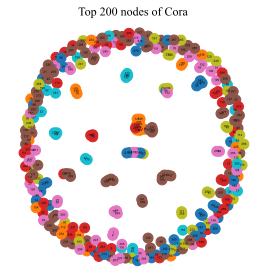

In [11]:
import networkx as nx
import matplotlib.pyplot as plt 
from deepspore.matplotlib_config import set_plt_rcParams
set_plt_rcParams()


# 2. 转换为 NetworkX 图
# data.edge_index 是 shape [2, num_edges]，需要转成边列表
edge_index = data.edge_index.numpy()
edges = list(zip(edge_index[0], edge_index[1]))

G = nx.Graph()   # Cora 是无向图
G.add_edges_from(edges)

# 3. 可视化（只画子图，否则节点太多）
plt.figure(figsize=(3.5, 3.5))
sub_nodes = list(range(300)) # 只取前 200 个节点的小子图
H = G.subgraph(sub_nodes)

# 用类别标签给节点上色
colors = [data.y[n].item() for n in H.nodes]
pos = nx.spring_layout(H, seed=42)  # spring layout
nx.draw(H, pos, node_color=colors, cmap=plt.cm.tab10, with_labels=True, node_size=100, font_size=3, edge_color="gray")
plt.title("Top 200 nodes of Cora")
plt.tight_layout()

In [12]:
import torch 
import torch.nn.functional as F
from torch_geometric.nn import GCNConv


class GCN(torch.nn.Module):
    def __init__(self, hidden_channels):
        super().__init__()
        self.conv1 = GCNConv(dataset.num_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, dataset.num_classes)
    
    def forward(self, x, edge_index):
        # print(x.shape, edge_index.shape)
        x = self.conv1(x, edge_index)
        # print(x.shape, edge_index.shape)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        # print(x.shape, edge_index.shape)
        return F.log_softmax(x, dim=1)


model = GCN(hidden_channels=16)

logit = model(x=data.x, edge_index=data.edge_index)
logit.shape

torch.Size([2708, 7])

In [13]:
import torch 


optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = torch.nn.NLLLoss()


def train():
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss

def test():
    model.eval()
    out = model(data.x, data.edge_index)
    pred = out.argmax(dim=1)
    accs = []
    for mask in [data.train_mask, data.val_mask, data.test_mask]:
        accs.append(int((pred[mask] == data.y[mask]).sum()) / int(mask.sum()))
    return accs

for epoch in range(1, 201):
    loss = train()
    train_acc, val_acc, test_acc = test()
    print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}, Train: {train_acc:.4f}, Val: {val_acc:.4f}')

Epoch: 001, Loss: 1.9457, Train: 0.3000, Val: 0.2300
Epoch: 002, Loss: 1.9389, Train: 0.4429, Val: 0.3780
Epoch: 003, Loss: 1.9302, Train: 0.3929, Val: 0.2980
Epoch: 004, Loss: 1.9220, Train: 0.3643, Val: 0.2660
Epoch: 005, Loss: 1.9115, Train: 0.3571, Val: 0.2560
Epoch: 006, Loss: 1.9024, Train: 0.3786, Val: 0.2900
Epoch: 007, Loss: 1.8870, Train: 0.4286, Val: 0.3240
Epoch: 008, Loss: 1.8745, Train: 0.5357, Val: 0.3780
Epoch: 009, Loss: 1.8672, Train: 0.6429, Val: 0.4400
Epoch: 010, Loss: 1.8487, Train: 0.7357, Val: 0.4940
Epoch: 011, Loss: 1.8387, Train: 0.7571, Val: 0.5480
Epoch: 012, Loss: 1.8276, Train: 0.7714, Val: 0.5680
Epoch: 013, Loss: 1.8153, Train: 0.7929, Val: 0.5780
Epoch: 014, Loss: 1.7900, Train: 0.8071, Val: 0.5860
Epoch: 015, Loss: 1.7867, Train: 0.8143, Val: 0.5980
Epoch: 016, Loss: 1.7618, Train: 0.8357, Val: 0.5960
Epoch: 017, Loss: 1.7469, Train: 0.8357, Val: 0.6020
Epoch: 018, Loss: 1.7405, Train: 0.8500, Val: 0.6160


Epoch: 019, Loss: 1.7196, Train: 0.8571, Val: 0.6220
Epoch: 020, Loss: 1.6970, Train: 0.8571, Val: 0.6320
Epoch: 021, Loss: 1.6699, Train: 0.8714, Val: 0.6400
Epoch: 022, Loss: 1.6695, Train: 0.8857, Val: 0.6580
Epoch: 023, Loss: 1.6434, Train: 0.9000, Val: 0.6720
Epoch: 024, Loss: 1.6129, Train: 0.9143, Val: 0.6940
Epoch: 025, Loss: 1.5899, Train: 0.9214, Val: 0.7040
Epoch: 026, Loss: 1.5774, Train: 0.9357, Val: 0.7120
Epoch: 027, Loss: 1.5765, Train: 0.9500, Val: 0.7120
Epoch: 028, Loss: 1.5424, Train: 0.9429, Val: 0.7100
Epoch: 029, Loss: 1.5077, Train: 0.9357, Val: 0.7060
Epoch: 030, Loss: 1.4948, Train: 0.9357, Val: 0.7080
Epoch: 031, Loss: 1.4841, Train: 0.9357, Val: 0.7200
Epoch: 032, Loss: 1.4782, Train: 0.9429, Val: 0.7240
Epoch: 033, Loss: 1.4270, Train: 0.9429, Val: 0.7220
Epoch: 034, Loss: 1.4157, Train: 0.9429, Val: 0.7320
Epoch: 035, Loss: 1.4004, Train: 0.9500, Val: 0.7360
Epoch: 036, Loss: 1.3684, Train: 0.9643, Val: 0.7420
Epoch: 037, Loss: 1.3730, Train: 0.9714, Val: 

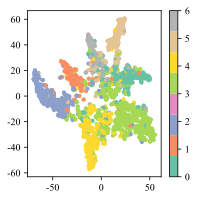

In [ ]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE


def visualize(h, color):
    z = TSNE(n_components=2).fit_transform(h.detach().cpu().numpy())
    
    plt.figure(figsize=(3,3))
    plt.scatter(z[:, 0], z[:, 1], s=10, c=color, cmap="Set2")
    plt.colorbar()
    plt.show()


# 训练后可视化
model.eval()
out = model(data.x, data.edge_index)
visualize(out, color=data.y)

# 4. <a id='toc4_'></a>[Data](#toc0_)

[Torch-geometric Working with graph dataset]()

torch_geometric.data
- Data
- Dataset
- InMemoryDataset

## 4.1. <a id='toc4_1_'></a>[Data](#toc0_)

Data 类：PyTorch Geometric 中的图数据通常被封装在 Data 类中，该类存储了图的节点特征、边信息和标签。

图（Graph）:
- 节点（Node）：表示图中的元素。
- 边（Edge）：连接节点的边，通常有方向性（有向图）或者无方向性（无向图）。
- 特征（Features）：节点或边可以有特征，表示该节点或边的属性。

图的表示:
- x：节点特征矩阵，形状为 (num_nodes, num_features)。
- edge_index：表示边的索引矩阵，形状为 (2, num_edges)，第一行是源节点，第二行是目标节点。
- y：图或节点的标签。

```python
# Node embeding
x = [[1,2,3,4,5], # Node 1
    [1,2,3,4,5],  # Node 2
    [1,2,3,4,5]]  # Node 3

# Node labels
y = [1, 4, 7] 

# Edge list, could be used to visualization
edge_index = [[0, 1, 1, 2, 3], # Target
              [1, 0, 0, 2, 1]] # Source

# Edge labels
edge_attr = [0, 1, 1, 3, 5]

# Mask for train
train_mask = [True, True, False, False]

# Mask for valid
valid_mask = [False, False, True, False]

# Mask for test
test_mask = [False, False, False, True]
```

Example:

```python
Data(
    x: Optional[torch.Tensor] = None,
    edge_index: Optional[torch.Tensor] = None,
    edge_attr: Optional[torch.Tensor] = None,
    y: Union[torch.Tensor, int, float, NoneType] = None,
    pos: Optional[torch.Tensor] = None,
    time: Optional[torch.Tensor] = None,
    **kwargs,
)
```

In [ ]:
from torch_geometric.data import Data
import torch 


# Synthetic data
# data = Data(x=torch.randn(4, 3), edge_index=torch.tensor([[0, 1, 2, 3, 0, 2],
#                                                          [1, 0, 3, 2, 2, 0]], dtype=torch.long))

# Same as above
## Node: x, y
## Edge: edge_index, edge_attr, edge_y
node_num = 4
node_hiddens = 3
node_label_classes = 8
data = Data(
    x=torch.randn(size=(node_num, node_hiddens)), 
    edge_index=torch.randint(low=0, high=node_num, size=(2, 6)),
    y=torch.randint(low=0, high=node_label_classes, size=(node_num,)),
    train_mask=torch.tensor([1]*(node_num//2)+[0]*(node_num//2)).bool(),
    # valid_mask=torch.tensor()
)  
data.x, data.edge_index, data.y, data.train_mask, data.x[data.train_mask]

(tensor([[-1.5141,  0.6308,  0.3316],
         [ 0.2159,  0.0786,  0.5006],
         [ 0.7080,  0.0350, -0.0316],
         [ 0.2922, -1.0338,  0.4183]]),
 tensor([[1, 0, 0, 0, 3, 1],
         [1, 2, 0, 2, 3, 3]]),
 tensor([7, 5, 5, 0]),
 tensor([ True,  True, False, False]),
 tensor([[-1.5141,  0.6308,  0.3316],
         [ 0.2159,  0.0786,  0.5006]]))

In [13]:
type(data)

torch_geometric.data.data.Data

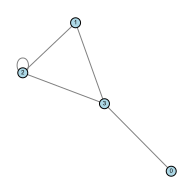

In [14]:
visualization(data.edge_index)

## 4.2. <a id='toc4_2_'></a>[dataset](#toc0_)

### 4.2.1. <a id='toc4_2_1_'></a>[Creating Graph Dataset](#toc0_)

[Creating graph datasetse](https://pytorch-geometric.readthedocs.io/en/latest/tutorial/create_dataset.html)

In [15]:
from torch_geometric.datasets import Planetoid 


dataset = Planetoid(root='./caches', name='Pubmed')
# dataset = Planetoid(root='./caches', name='Cora')

In [16]:
# dataset.data
type(dataset), len(dataset), dataset.data

/bmp/backup/zhaosy/miniconda3/envs/dl/lib/python3.11/site-packages/torch_geometric/data/in_memory_dataset.py:300: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  warnings.warn(msg)


(torch_geometric.datasets.planetoid.Planetoid,
 1,
 Data(x=[19717, 500], edge_index=[2, 88648], y=[19717], train_mask=[19717], val_mask=[19717], test_mask=[19717]))

### 4.2.2. <a id='toc4_2_2_'></a>[Dataset split](#toc0_)

[Dataset split](https://pytorch-geometric.readthedocs.io/en/latest/tutorial/dataset_splitting.html)

## 4.3. <a id='toc4_3_'></a>[visualization](#toc0_)

### 4.3.1. <a id='toc4_3_1_'></a>[Networkx](#toc0_)

Spend about `25` mins:

In [17]:
import networkx as nx 


G = nx.Graph()
G.add_edges_from(dataset.data.edge_index.T.tolist()) # 转成 [(u,v), ...] 列表
# G = G.subgraph(nodes=list(range(500)))

plt.figure(figsize=(8, 6))
nx.draw(G, pos=nx.spring_layout(G, seed=123), node_size=50, node_color='lightblue', with_labels=True,  font_size=6)

### 4.3.2. <a id='toc4_3_2_'></a>[Pyhton-igraph](#toc0_)

Spend about `6` mins:

In [18]:
import igraph as ig


# 1. 从 PyG dataset 获取边信息
edges = dataset.data.edge_index.T.tolist()  # 转成 [(u,v), ...] 列表
num_nodes = dataset.data.num_nodes

# 2. 创建 igraph Graph
G = ig.Graph(n=num_nodes, edges=edges, directed=False)

# 如果只画子图（比如前500个节点）
# G = G.subgraph(list(range(500)))

# 3. 布局（类似 networkx.spring_layout）
layout = G.layout("fruchterman_reingold")  # 力导向布局

# 4. 可视化
fig, ax = plt.subplots(figsize=(8, 6))
ig.plot(
    G,
    layout=layout,
    target=ax,              # 绘制到 matplotlib Axes
    vertex_size=5,          # 节点大小
    vertex_color="lightblue",
    vertex_label=[str(v) for v in range(G.vcount())],  # 标签
    vertex_label_size=6,    # 字体大小
    edge_color="gray"
)


/bmp/backup/zhaosy/miniconda3/envs/dl/lib/python3.11/site-packages/torch_geometric/data/in_memory_dataset.py:300: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  warnings.warn(msg)


## 4.4. <a id='toc4_4_'></a>[dataloader](#toc0_)

In [19]:
from torch_geometric.loader import DataLoader


loader = DataLoader(dataset, batch_size=8, num_workers=8)

In [20]:
for batch in loader:
    print(batch)
    break

DataBatch(x=[19717, 500], edge_index=[2, 88648], y=[19717], train_mask=[19717], val_mask=[19717], test_mask=[19717], batch=[19717], ptr=[2])


# 5. <a id='toc5_'></a>[Model](#toc0_)

In [19]:
from torch_geometric.nn import GCNConv, GATConv, SAGEConv, ChebConv, GINConv

# 6. <a id='toc6_'></a>[Train](#toc0_)